# Gaussian Process Regression — skeleton

Complete every `TODO`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

## RBF kernel

$$k(x, x') = \sigma^2 \exp\left(-\frac{(x - x')^2}{2\ell^2}\right)$$

In [3]:
def rbf(x1, x2, length_scale=1.0, variance=1.0):
    # TODO: matrix of pairwise differences x1_i - x2_j (shape len(x1) x len(x2)), use broadcasting
    d = x1[:, None] - x2[None, :]
    # TODO: return the RBF kernel matrix
    return variance * np.exp(-((d)**2)/(2*length_scale**2))

## Prior at the test points $X_*$

$$f_* \sim \mathcal{N}\big(0,\; K(X_*, X_*)\big)$$

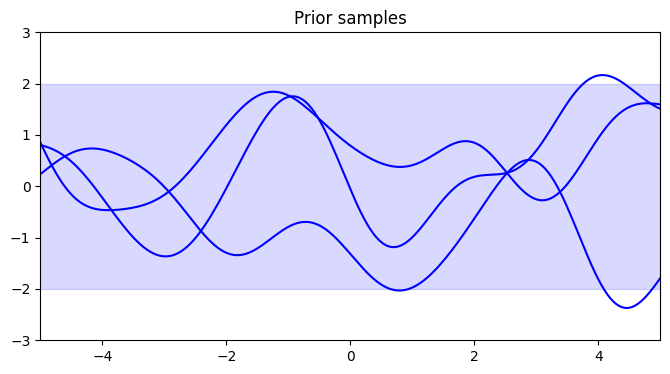

In [4]:
x = np.linspace(-5, 5, 200)

# TODO: prior mean 
mu_prior = np.zeros(len(x))
# TODO: prior covariance 
Sigma_prior = rbf(x,x,1,1)
# TODO: pointwise standard deviation 
std_prior = np.array([Sigma_prior[i,i]**(1/2) for i in range(Sigma_prior.shape[0])])
# std_prior.shape

# TODO: draw 3 samples
f_prior = np.random.multivariate_normal(mu_prior, Sigma_prior, 3)

plt.figure(figsize=(8, 4))
# TODO: shade the band mean ± 2·std
plt.fill_between(x, -2*std_prior, 2*std_prior, color="blue", alpha=0.15)
plt.plot(x, f_prior.T, color="blue")
plt.xlim(-5, 5); plt.ylim(-3, 3)
plt.title("Prior samples");

## Training data $(X, f)$

$$f = \sin(X)$$

Joint prior:

$$\begin{bmatrix} f \\ f_* \end{bmatrix} \sim \mathcal{N}\left(0,\; \begin{bmatrix} K(X,X) & K(X,X_*) \\ K(X_*,X) & K(X_*,X_*) \end{bmatrix}\right)$$

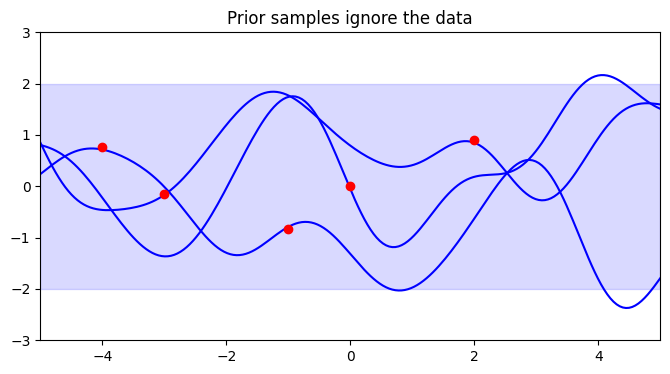

In [5]:
X_train = np.array([-4.0, -3.0, -1.0, 0.0, 2.0])
# TODO: noise-free observations f = sin(X)
f_train = np.sin(X_train)

plt.figure(figsize=(8, 4))
plt.fill_between(x, -2, 2, color="blue", alpha=0.15)
plt.plot(x, f_prior.T, color="blue")
plt.plot(X_train, f_train, "o", color="red")
plt.xlim(-5, 5); plt.ylim(-3, 3)
plt.title("Prior samples ignore the data");

## Posterior

$$f_* \mid X_*, X, f \;\sim\; \mathcal{N}\Big(K(X_*, X)\,K(X, X)^{-1} f,\;\; K(X_*, X_*) - K(X_*, X)\,K(X, X)^{-1}K(X, X_*)\Big)$$

In [6]:
f_train.shape

(5,)

Text(0.5, 1.0, 'Posterior samples')

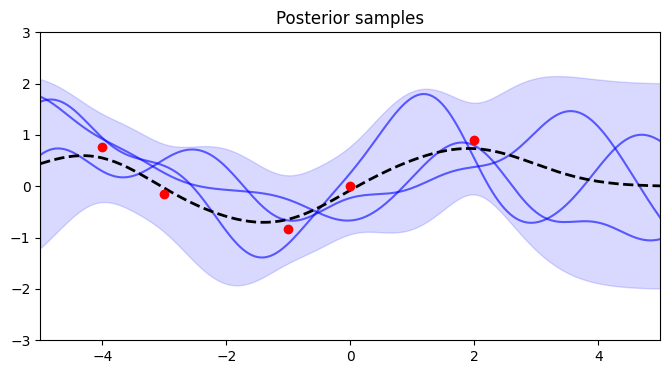

In [7]:
import numpy as np
X_test = np.linspace(-5, 5, 200)

# TODO: the three kernel blocks
K_ss = rbf(X_test, X_test)   # K(X*, X*)
# K    = rbf(X_train, X_train)    # K(X, X)
sigma = 0.5
K    = rbf(X_train, X_train) + sigma**2 * np.eye(len(X_train))    # K(X, X) con ruido
K_s  = rbf(X_test, X_train)   # K(X*, X)

# TODO: posterior mean  (hint: np.linalg.solve instead of inv)
mu_post  = K_s@np.linalg.solve(K, f_train)
# TODO: posterior covariance
cov_post = K_ss - K_s@np.linalg.solve(K, np.eye(K.shape[0]))@K_s.T
# cov_post
# TODO: posterior std 
std_post = np.array([cov_post[i,i]**(1/2) for i in range(cov_post.shape[0])])
# TODO: draw 3 posterior samples 
f_post = np.random.multivariate_normal(mu_post, cov_post, 3)

plt.figure(figsize=(8, 4))
# TODO: shade the band mu_post ± 2·std_post
plt.fill_between(X_test, mu_post - 2* std_post, mu_post+ std_post*2, color="blue", alpha=0.15)
plt.plot(X_test, f_post.T, color="blue", alpha=0.6)
plt.plot(X_test, mu_post, "k--", lw=2, label="Posterior mean")
plt.plot(X_train, f_train, "o", color="red", label="Training data")
plt.xlim(-5, 5); plt.ylim(-3, 3)
plt.title("Posterior samples")
# plt.legend();